In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [61]:
def power_law(m, A, alpha):
    return A * m**alpha

In [62]:
def compute_cumulative_outcome_fractions(df, masses, N):
    """
    df      : DataFrame with columns ['mass', 'time', 'particle_id', 'result']
              where result is 'Ejected' or 'Captured', and each row represents
              the time at which that particle's outcome occurred
    masses  : list/array of unique mass values, in the same order as N
    N       : list/array of total particle counts, one per mass in `masses`

    Returns
    -------
    ejection_df, capture_df : DataFrames indexed by mass, columns = sorted
                               unique time values, entries = CUMULATIVE
                               fraction of N with that result by that time
                               (i.e. fraction ejected/captured at or before
                               each time, monotonically non-decreasing
                               across each row)
    """
    if len(masses) != len(N):
        raise ValueError("masses and N must be the same length")

    mass_to_N = dict(zip(masses, N))

    times = np.sort(df["time"].unique())

    ejection_df = pd.DataFrame(index=masses, columns=times, dtype=float)
    capture_df = pd.DataFrame(index=masses, columns=times, dtype=float)

    for mass in masses:
        mass_df = df[df["mass"] == mass]
        denom = mass_to_N[mass]

        counts = (
            mass_df.groupby(["time", "result"])
            .size()
            .unstack(fill_value=0)
        )

        # reindex to the full sorted time axis, filling any missing times
        # with 0 new outcomes at that time, then cumsum across time
        ejected_counts = counts.get("Ejected", pd.Series(0, index=counts.index))
        captured_counts = counts.get("Captured", pd.Series(0, index=counts.index))

        ejected_counts = ejected_counts.reindex(times, fill_value=0)
        captured_counts = captured_counts.reindex(times, fill_value=0)

        ejection_df.loc[mass] = (ejected_counts.cumsum() / denom).values
        capture_df.loc[mass] = (captured_counts.cumsum() / denom).values

    return ejection_df, capture_df

In [63]:
df_1=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2188349_ejection_results.txt', header=None)
df_1_lm_1=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2215154_ejection_results.txt', header=None)
df_1_lm_2=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results_Restarted/2215154/2215154_mass_7.94328235e-05_restarted_results.txt', header=None)

In [64]:
df_i_5=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Particle_Tracking/2215154-1_initial_particles.txt')

In [65]:
df_i_5.columns=['a','e','id']

(array([77., 69., 88., 92., 81., 86., 82., 62., 77., 85.]),
 array([0.60121384, 0.74099489, 0.88077593, 1.02055698, 1.16033803,
        1.30011907, 1.43990012, 1.57968117, 1.71946221, 1.85924326,
        1.99902431]),
 <BarContainer object of 10 artists>)

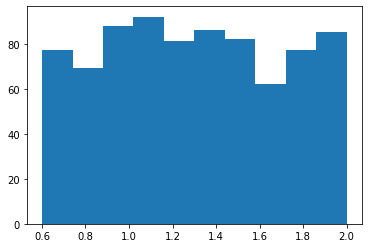

In [66]:
plt.hist(df_i_5.a)

In [67]:
df_1_interval=(0.5,2.5)
df_1_lm_interval=(0.6,2.0)

In [68]:
df_1.columns = ['mass', 'time', 'result', 'particle_id']
df_1_lm_1.columns = ['mass', 'time', 'result', 'particle_id']
df_1_lm_2.columns= ['mass', 'time', 'result', 'particle_id']

In [69]:
df_1_lm=pd.concat([df_1_lm_1,df_1_lm_2])

In [133]:
df_1_lm

,mass,time,result,particle_id
0,0.000158,0.000000e+00,Captured,140
1,0.000079,3.799849e+04,Captured,163
2,0.000158,3.099754e+04,Ejected,360
3,0.000158,7.899374e+04,Captured,483
4,0.000158,7.999366e+04,Captured,530
...,...,...,...,...
22,0.000079,1.370546e+07,Ejected,260
23,0.000079,1.392045e+07,Ejected,450
24,0.000079,1.394045e+07,Ejected,202
25,0.000079,1.417344e+07,Ejected,675


In [70]:
target = 7.94328235e-05

df_1_lm.loc[np.isclose(df_1_lm['mass'], target), 'mass'] = target

In [71]:
ejection_df_1, capture_df_1 = compute_cumulative_outcome_fractions(df_1, df_1.mass.unique(), N=[800,800,800,800,800,800])
ejection_df_1_lm,capture_df_1_lm=compute_cumulative_outcome_fractions(df_1_lm,df_1_lm.mass.unique(), N=[800,800,800,800,800])

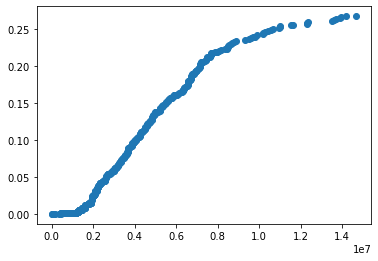

In [138]:
plt.scatter(ejection_df_1_lm.columns,ejection_df_1_lm.loc[ejection_df_1_lm.index[1]])

In [72]:
files=[
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_0.csv',
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_1.csv',
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_2.csv',
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_3.csv',
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_4.csv',
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_5.csv',

]

In [73]:
remaining_df_1=pd.DataFrame()
for file in files:
    temp_df=pd.read_csv(file)
    print(temp_df)
    remaining_df_1=pd.concat([remaining_df_1,temp_df], ignore_index=True)

     m_planet           time                   a         e
0        0.01  231843.665319  0.5089722881201106  0.084216
1        0.01  231843.665319   0.620409418940917  0.035911
2        0.01  231843.665319  2.3822393205381274  0.086349
3        0.01  231843.665319  2.0986857079055286  0.079524
4        0.01  231843.665319  1.5648132883096946  0.063681
..        ...            ...                 ...       ...
342      0.01  231843.665319  2.0449604034765905  0.207570
343      0.01  231843.665319  1.8606264991877275  0.081027
344      0.01  231843.665319  2.2857738984481473  0.125663
345      0.01  231843.665319   1.975885280915687  0.071762
346      0.01  231843.665319    2.37385280310965  0.249165

[347 rows x 4 columns]
     m_planet           time                   a         e
0    0.005012  278303.460942  1.9177560825596134  0.162057
1    0.005012  278303.460942  2.4896096587038623  0.094540
2    0.005012  278303.460942  2.2594893075761946  0.151854
3    0.005012  278303.460942    

In [103]:
left_counts = ejection_df_1[ejection_df_1.columns[-1]]*800

unbound_counts = (
    remaining_df_1.groupby("m_planet")["a"]
    .apply(lambda x: (x == "Unbound").sum())
)


total_affected = left_counts.add(unbound_counts, fill_value=0)

In [106]:
left_counts

0.002512    303.0
0.000631    196.0
0.010000    447.0
0.005012    322.0
0.001259    235.0
0.000316    169.0
Name: 2019680.6856863664, dtype: float64

In [124]:
fit_fracs_unscaled=pd.concat([total_affected/800,ejection_df_1_lm[ejection_df_1_lm.columns[-1]]])
fit_fracs_unscaled.sort_index(inplace=True,ascending=False)

In [125]:
fit_fracs_unscaled

0.010000    0.57000
0.005012    0.42250
0.002512    0.39125
0.001259    0.29875
0.000631    0.25000
0.000316    0.21125
0.000158    0.27875
0.000079    0.26750
0.000040    0.04500
0.000020    0.01250
0.000010    0.00625
dtype: float64

In [126]:
fit_fracs=fit_fracs_unscaled
fit_fracs = fit_fracs.iloc[:-3]

In [127]:
fit_fracs.loc[fit_fracs.index < 0.0003] *= 0.7

In [128]:
fit_fracs

0.010000    0.570000
0.005012    0.422500
0.002512    0.391250
0.001259    0.298750
0.000631    0.250000
0.000316    0.211250
0.000158    0.195125
0.000079    0.187250
dtype: float64

In [129]:
popt,pcov=curve_fit(power_law,fit_fracs.index,fit_fracs)

In [132]:
np.sqrt(((1-0.195125)*0.195125)/800)

0.01401121133124292

In [130]:
fit_fracs_lower_error=np.sqrt(((1-fit_fracs)*fit_fracs)/800)
fit_fracs_upper_error=fit_fracs_lower_error+0.04/3

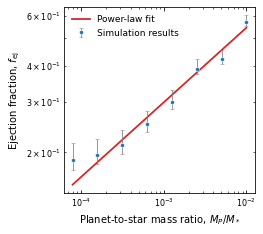

In [131]:
# plt.scatter(fit_fracs.index,fit_fracs)
cm = 1/2.54  # centimeters in inches
fig, ax = plt.subplots(1, 1, tight_layout=False,figsize=(8.7*cm,8.7*cm),sharex=False,sharey=False
                       ,gridspec_kw={'hspace': 0.35, 'wspace': 0.3})

# Data and asymmetric error bars
ax.errorbar(
    fit_fracs.index,
    fit_fracs,
    yerr=[fit_fracs_lower_error, fit_fracs_upper_error],
    fmt='o',
    markersize=4,
    color='tab:blue',
    ecolor='gray',
    elinewidth=0.8,
    capsize=2,
    capthick=0.8,
    markeredgecolor='white',
    markeredgewidth=0.5,
    label='Simulation results',
    zorder=3
)

# Power-law fit
x = np.logspace(-4.1, -2, 300)
a, b = popt
y = power_law(x, a, b)

ax.plot(
    x, y,
    color='tab:red',
    linewidth=1.8,
    label='Power-law fit',
    zorder=2
)

# Logarithmic axes
ax.set_xscale('log')
ax.set_yscale('log')


ax.set_xlabel(r'Planet-to-star mass ratio, $M_P/M_*$', fontsize=10)
ax.set_ylabel(r'Ejection fraction, $f_{\mathrm{ej}}$', fontsize=10)

# Ticks
ax.tick_params(
    axis='both',
    which='both',
    direction='in',
    top=True,
    right=True,
    labelsize=8
)

ax.minorticks_on()

# Subtle horizontal grid
ax.grid(
    axis='y',
    which='major',
    linestyle=':',
    alpha=0.25
)

ax.legend(frameon=False, fontsize=9)

# ax.set_yticks([0.2, 0.3, 0.4, 0.5, 0.6])
# ax.set_yticklabels(['0.2', '0.3', '0.4', '0.5', '0.6'])

#fig.tight_layout()
#plt.savefig('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Visualizations/f_ej_fit_errorbars.png', facecolor='white',bbox_inches='tight', dpi=500)